## Open Tools, Open Sky
### Doing LSST Science with Public Rubin Data & LINCC Frameworks
#### **Latest update**: Oct. 15 / 2026, 1:00 am, Jorge I. Zuluaga

## Exploring the light-curve of a selected asteroid

The purpose of this notebook is to explore manually the observations of VRO of a given asteroid.

### Tools required

In [1]:
# !pip install -Uq sorcha layup rebound pymcel pyarrow multimin alerce pyvo scikit-learn gdown
# !gdown 1mAUEoHxpvZk0HqeZe4wgOIcZMi-tYemy # util.py

In [ ]:
from zuluaga_dev.util import *
import requests
import pandas as pd
import os
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq
from astroquery.jplsbdb import SBDB
import matplotlib.dates as mdates
from astropy.timeseries import LombScargle
import re
from scipy.signal import find_peaks

# Macros
DEG = np.pi / 180
RAD = 1 / DEG

# Directories
fig_dir='figures/'
data_dir='zuluaga_dev/data/'
!mkdir -p %data_dir %fig_dir

# Reload util.py routines
%load_ext autoreload 
%autoreload 2

# Check that data files exists
get_data(data_dir = data_dir)

Data already exists: zuluaga_dev/data/obs_sbn_X05_full.parquet
Data already exists: zuluaga_dev/data/mpcorb_extended.dat.gz
Data already exists: zuluaga_dev/data/asteroids-with-rotation.csv
Data already exists: zuluaga_dev/data/X05_simplified.csv
Download complete or files already present.


### Prepare data

In [3]:
columns = [
    'obstime', 'permid', 'provid',
    'ra', 'dec', 'band', 'mag', 'rmsmag'
]

data_file = data_dir + 'obs_sbn_X05_full.parquet'
df_full = pd.read_parquet(
    data_file,
    columns=columns,
)
print(f"Original number of observations: {len(df_full)}")

# Filter observations with provid or permid
df_set = df_full[~(df_full['provid'].isna() & df_full['permid'].isna())].reset_index(drop=True)
print(f"Number of observations with provid or permid: {len(df_set)}")

# Filter observations with asteroid provid
asteroid_provid_pattern = re.compile(r'^\d{4} [A-Z]{2}\d+[A-Z]?$')
df_set = df_set[df_set['provid'].apply(lambda pid: bool(asteroid_provid_pattern.match(str(pid))))].reset_index(drop=True)
print(f"Number of observations with asteroid provid: {len(df_set)}")

provids = df_set['provid'].dropna().unique()
permids = df_set['permid'].dropna().unique()
bothids = df_set.dropna(subset=['permid','provid'])['provid'].unique()
print(f"Number of objects with provid:  {len(provids)}")
print(f"Number of objects with permid: {len(permids)}")
print(f"Number of objects with both ids: {len(bothids)}")

# Change label for filters
df_set['band'] = df_set['band'].apply(lambda b: f"L{b}" if pd.notnull(b) and len(str(b)) == 1 else b)
band_columns_to_remove = ['r', 'g', 'i', 'z', 'y', 'u']
df_set = df_set.drop(columns=[col for col in band_columns_to_remove if col in df_set.columns])

# Sort observations
df_set = df_set.sort_values(
    by=['provid', 'band', 'obstime'],
    ascending=[True, True, True]
).reset_index(drop=True)

# Convert data
cols = ['ra', 'dec', 'mag', 'rmsmag']
df_set[cols] = df_set[cols].apply(pd.to_numeric, errors='coerce')
df_set['night'] = df_set['obstime'].dt.floor('D')

del(df_full)
total_sizeof_globals()

Original number of observations: 8078546
Number of observations with provid or permid: 8014721
Number of observations with asteroid provid: 7870711
Number of objects with provid:  297318
Number of objects with permid: 176882
Number of objects with both ids: 176903
Total RAM used by notebook variables: 654.42 MB


### Asteroid data

In [16]:
#provid = '2001 WF82'
#provid = '2002 AV174'
#provid = '2002 DE21'
provid = '2002 TF75'

# Physical properties from JPL SBDB (only those that are available).
target = provid
sbdb = SBDB.query(str(target), phys=True)
phys = sbdb.get('phys_par') or {}
obj = sbdb.get('object') or {}
print(obj.get('fullname') or obj.get('des') or target)

rows = []
for key, value in phys.items():
    if key.endswith(('_sig', '_ref', '_note')) or value in (None, ''):
        continue
    rows.append({
        'parameter': key,
        'value': value,
        'sigma': phys.get(f'{key}_sig'),
        'reference': phys.get(f'{key}_ref'),
        'note': phys.get(f'{key}_note'),
    })

df_phys = pd.DataFrame(rows)
if df_phys.empty:
    print(f'No physical properties in SBDB for {target}.')
else:
    print(df_phys.to_string(index=False))

# Observations
df_obj = df_set[(df_set['provid'] == provid)].copy()
print(f"Number of observations: {len(df_obj)}")

t0 = df_obj['obstime'].iloc[0]
df_obj['t_days'] = (df_obj['obstime'] - t0).dt.total_seconds() / 86400.0

print(f"Total observations of Asteroid {provid}: {len(df_obj)}")
print(f"Observing arc: {(df_obj['obstime'].max() - t0).total_seconds() / 86400.0:.2f} days")
print(f"Observations per band: {df_obj['band'].value_counts().to_dict()}")

# Absolute magnitudes
datafile = data_dir + "obs_final_elements_geometry_H.parquet"
designation = mpc_designation_for(df_set, provid, datafile)
print(f"{provid} -> {designation}")
table = pq.read_table(
    data_dir + "obs_final_elements_geometry_H.parquet",
    columns=["obstime", "a", "e", "q", "incl", "node", "peri", "M", "r", "delta", "phase_angle", "mag", "H"],
    filters=[("mpc_designation", "==", designation)],
)
df_spy = table.to_pandas()
print(f"Total number of observations with absolute magnitudes: {len(df_spy)}")

# Merge df_spy into df_obj on the 'obstime' column
df_obj = pd.merge(df_obj, df_spy, on='obstime', how='left', suffixes=('', '_spy'))

176815 (2002 TF75)
parameter  value sigma reference note
        H  16.68  None MPO966757 None
Number of observations: 617
Total observations of Asteroid 2002 TF75: 617
Observing arc: 9.07 days
Observations per band: {'Lr': 223, 'Lg': 172, 'Li': 154, 'Lu': 68}
2002 TF75 -> (176815) 2002 TF75
Total number of observations with absolute magnitudes: 617


### Periodogram

Photometric period: 3.37 hours
Derived asteroid rotation period: 6.75 hours

All periodogram peaks with >80% of main peak power:
[0] Rotational Period = 9.41 h | Power = 0.838
[1] Rotational Period = 7.86 h | Power = 0.970
[2] Rotational Period = 6.75 h | Power = 1.000
[3] Rotational Period = 5.91 h | Power = 0.936
[4] Rotational Period = 5.26 h | Power = 0.812


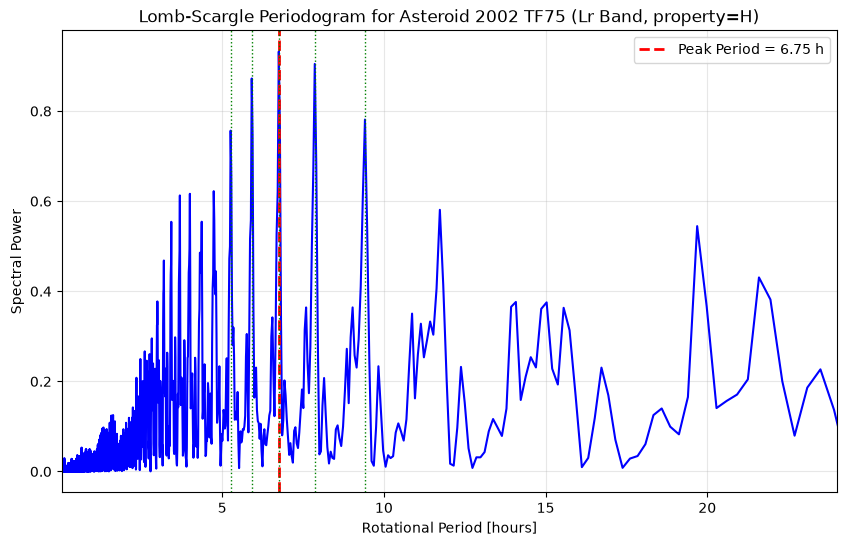

In [17]:
band = 'Lr'
prop = 'H'

df_band = df_obj[df_obj['band'] == band].copy()
t_band = df_band['t_days'].values
y_band = df_band[prop].values
dy_band = df_band['rmsmag'].fillna(0.01).values

# Frequency grid: 1.0 to 10.0 cycles/day (corresponding to periods from 2.4 to 24 hours)
periods = [2/60, 24] # in hours
freq_grid = np.linspace(24/periods[1], 24/periods[0], 20000)
ls_band = LombScargle(t_band, y_band, dy_band)
power = ls_band.power(freq_grid)

main_peak_power = np.max(power)
best_freq = freq_grid[np.argmax(power)]
best_phot_period = 24.0 / best_freq
best_rot_period = 2.0 * best_phot_period  # Double-peaked rotational period
print(f"Photometric period: {best_phot_period:.2f} hours")
print(f"Derived asteroid rotation period: {best_rot_period:.2f} hours")

# Find periodogram peaks
peaks, _ = find_peaks(power)
threshold = 0.8 * main_peak_power
high_power_indices = np.where(power >= threshold)[0]
high_power_peaks = np.intersect1d(peaks, high_power_indices)

print(f"\nAll periodogram peaks with >80% of main peak power:")

all_rot_periods = []
peak_data = []
for i, idx in enumerate(high_power_peaks):
    freq = freq_grid[idx]
    ph_per = 24.0 / freq
    rot_per = 2.0 * ph_per
    rel_pwr = power[idx] / main_peak_power
    all_rot_periods = np.append(all_rot_periods, rot_per)
    peak_data.append({
        "frequency": freq,
        "rotational_period_h": rot_per,
        "relative_power": rel_pwr
    })
    print(f"[{i}] Rotational Period = {rot_per:.2f} h | Power = {rel_pwr:.3f}")
df_peaks = pd.DataFrame(peak_data).sort_values(by='relative_power', ascending=False).reset_index(drop=True) 

fig, ax = plt.subplots(figsize=(10, 6))

period_grid_hours = (24.0 / freq_grid) * 2.0  # Converted to rotational period
ax.plot(period_grid_hours, power, color='b', lw=1.5)
ax.axvline(best_rot_period, color='r', linestyle='--', lw=2, label=f'Peak Period = {best_rot_period:.2f} h')
for period in all_rot_periods:
    ax.axvline(period, color='g', linestyle=':', alpha=1, lw=1)

ax.set_xlabel('Rotational Period [hours]')
ax.set_ylabel('Spectral Power')
ax.set_title(f'Lomb-Scargle Periodogram for Asteroid {provid} ({band} Band, property={prop})')
ax.set_xlim(periods[0], periods[1])
ax.legend(loc='upper right', frameon=True)
ax.grid(True, alpha=0.3)
fig.savefig(fig_dir + f"periodogram_{provid.replace(' ', '_')}.png", dpi=300)

### Folded and normalized light-curve

[0] Rotational Period = 6.75 h | Power = 1.000
Brightest magnitude of each filter (m_max):
  Lu: 17.837
  Lg: 16.781
  Lr: 16.152
  Li: 15.987


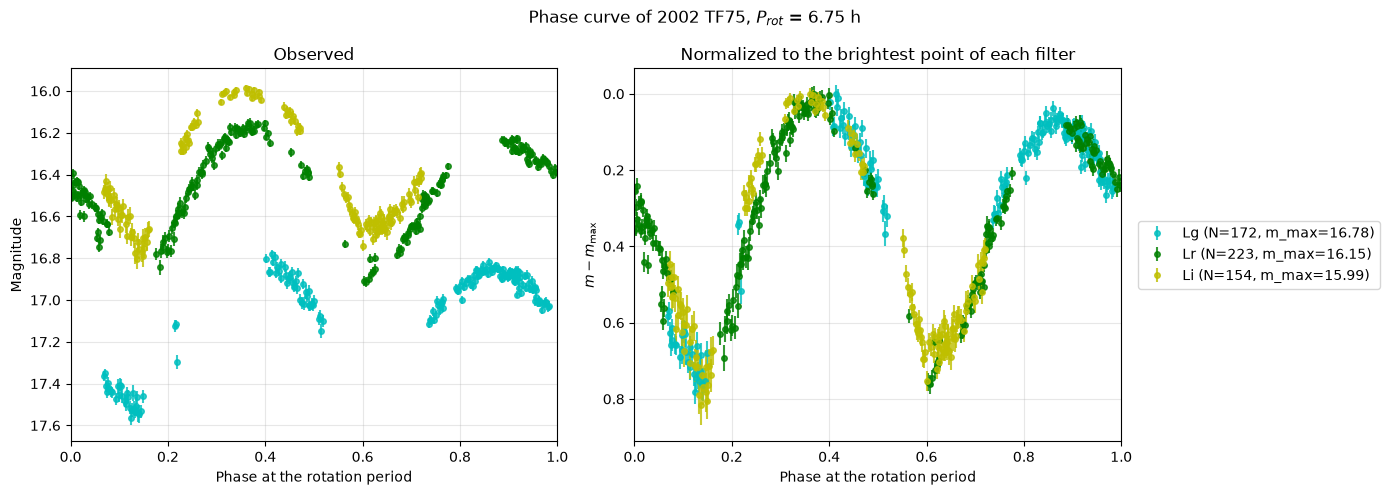

In [22]:
isel = 0
freq_sel = df_peaks.iloc[isel]['frequency']
per_sel = df_peaks.iloc[isel]['rotational_period_h']
rel_pwr = df_peaks.iloc[isel]['relative_power']
print(f"[{isel}] Rotational Period = {per_sel:.2f} h | Power = {rel_pwr:.3f}")

present = [b for b in ALL_BANDS if (df_obj['band'] == b).any()]
m_max = {}
for b in present:
    m_max[b] = df_obj[df_obj['band'] == b][prop].min()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
print('Brightest magnitude of each filter (m_max):')
for b, m in m_max.items():
    print(f'  {b}: {m:.3f}')

t0 = t_band.min()
for b in present:
    if b == 'Lu': continue
    sb = df_obj[df_obj['band'] == b]
    phase_b = np.mod((sb['t_days'].to_numpy() - t0) * freq_sel / 2.0, 1.0)
    dy = sb['rmsmag'].fillna(0.01)
    marker = 'o' if b.startswith('L') else 's'
    m = m_max[b]
    style = dict(fmt=marker, ms=4, alpha=0.8, color=band_colors.get(b, 'k'),
                 label=f'{b} (N={len(sb)}, m_max={m:.2f})')
    axes[0].errorbar(phase_b, sb[prop], yerr=dy, **style)
    axes[1].errorbar(phase_b, sb[prop] - m, yerr=dy, **style)

axes[0].set_ylabel('Magnitude')
axes[0].set_title('Observed')
axes[1].set_ylabel(r'$m - m_{\mathrm{max}}$')
axes[1].set_title('Normalized to the brightest point of each filter')
for ax in axes:
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel('Phase at the rotation period')
    ax.grid(True, alpha=0.3)
axes[1].legend(loc='center left', bbox_to_anchor=(1.02, 0.5), frameon=True)
fig.suptitle(f'Phase curve of {provid}, $P_{{rot}}$ = {per_sel:.2f} h')
fig.tight_layout()
fig.savefig(fig_dir + f'phase_allbands_{provid.replace(" ", "_")}.png', dpi=300)


### Other plots

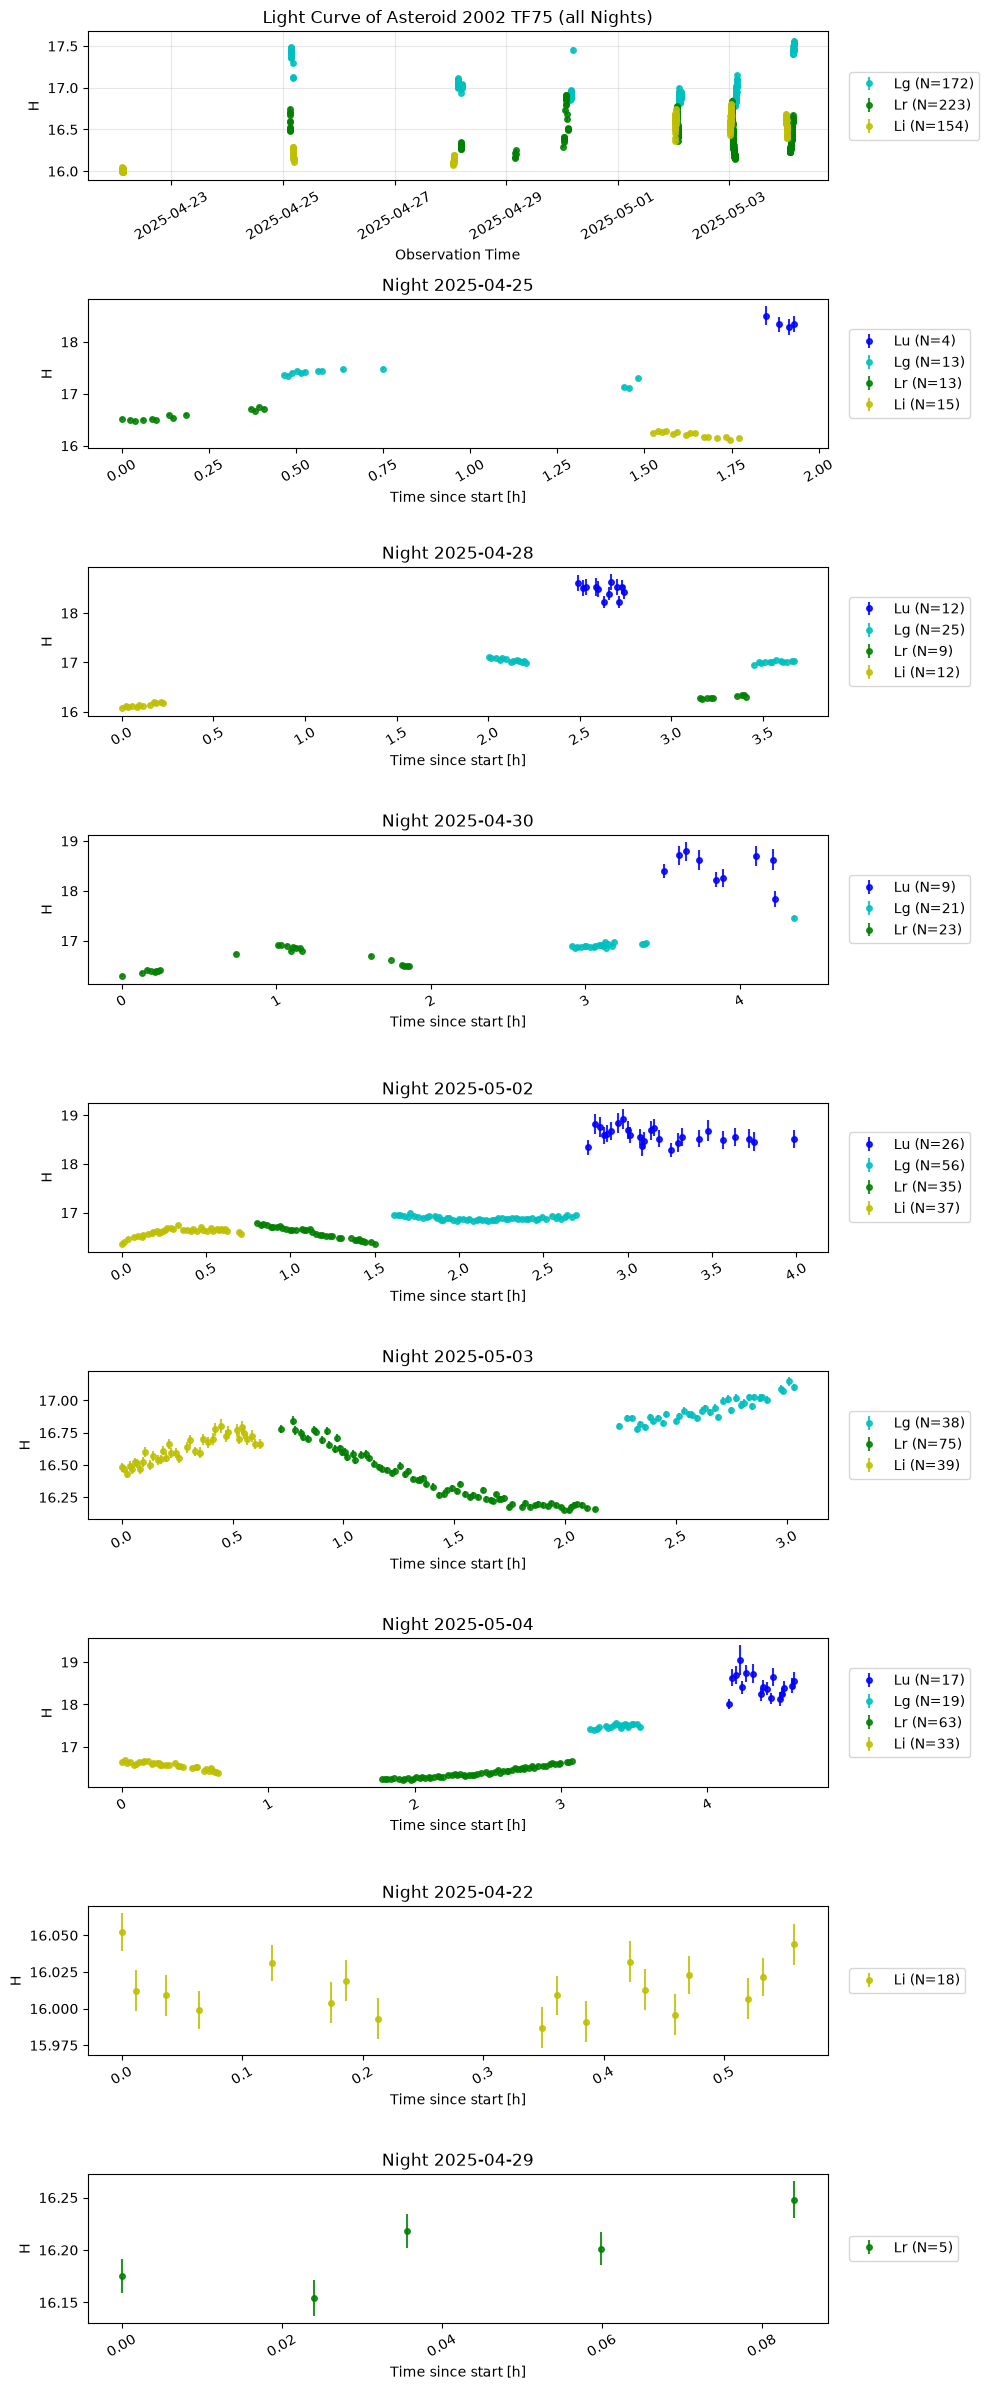

In [23]:
verbose = 0
nights = df_obj.night.unique()
n_nights = len(nights)

fig, axs = plt.subplots(n_nights + 1, 1, figsize=(10, 3*n_nights))

# All data
ax = axs[0]
df_obj = df_obj.copy()
for b in BANDS:
    sb = df_obj[df_obj['band'] == b]
    if len(sb) > 0:
        ax.errorbar(sb['obstime'], sb['H'], yerr=sb['rmsmag'], fmt='o', 
                     label=f'{b} (N={len(sb)})', color=band_colors.get(b, 'k'), markersize=4, alpha=0.85)

ax.set_xlabel(f"Observation Time")
ax.set_ylabel('H')
ax.tick_params(axis='x', rotation=30)
ax.set_title(f"Light Curve of Asteroid {provid} (all Nights)")
ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=1, frameon=True)
ax.grid(True, alpha=0.3)

for i, night in enumerate(nights):
    night_str = pd.to_datetime(night).strftime('%Y-%m-%d')
    if verbose:print(f"Processing night {night_str}")
    ax = axs[i+1]
    t_night = df_obj[df_obj['night'] == night].copy()
    t_night_0 = min(t_night['obstime'])
    t_night['h'] = (t_night['obstime'] - t_night_0).dt.total_seconds() / 3600.0
    for b in ALL_BANDS:
        sb = t_night[t_night['band'] == b]
        if len(sb) > 0:
            if verbose:print(f"\tBand {b}: {len(sb)} observations")
            ax.errorbar(sb['h'], sb['H'], yerr=sb['rmsmag'], fmt='o', 
                        label=f'{b} (N={len(sb)})', color=band_colors.get(b, 'k'), markersize=4, alpha=0.85)
    
    ax.set_title(f"Night {night_str}")
    ax.set_xlabel(f"Time since start [h]")
    ax.set_ylabel('H')
    ax.legend(loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=1, frameon=True)
    ax.tick_params(axis='x', rotation=30)

fig.tight_layout()
fig.savefig(fig_dir + f"lightcurve_allnights_H_{provid.replace(' ', '_')}.png", dpi=300)

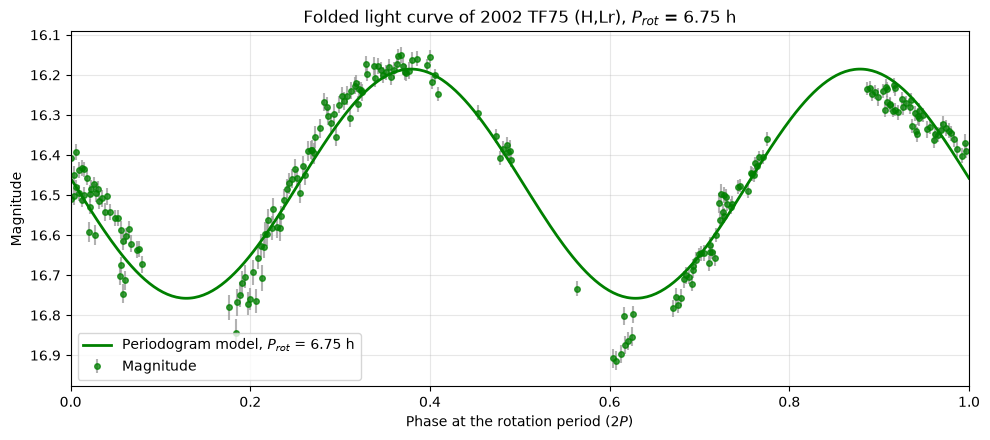

In [24]:
t0 = t_band.min()
phase = np.mod((t_band - t0) * freq_sel, 1.0)
phase_grid = np.linspace(0, 1, 400)
y_model = ls_band.model(t0 + phase_grid / freq_sel, freq_sel)

# Same model sampled across one rotation (two photometric cycles)
phase_rot = np.mod((t_band - t0) * freq_sel / 2.0, 1.0)
phase_rot_grid = np.linspace(0, 1, 400)
y_model_rot = ls_band.model(t0 + phase_rot_grid * 2.0 / freq_sel, freq_sel)

fig, ax = plt.subplots(1, 1, figsize=(10, 4.5))

b = band if isinstance(band, str) else band[0]
curve_color = band_colors.get(b, 'k')
ax.errorbar(
    phase_rot, y_band, yerr=dy_band, fmt='o', ms=4, alpha=0.75,
    color=curve_color, ecolor='0.6', label='Magnitude'
)
ax.plot(
    phase_rot_grid, y_model_rot, color=curve_color, lw=2,
    label=f'Periodogram model, $P_{{rot}}$ = {best_rot_period:.2f} h'
)
ax.set_xlabel('Phase at the rotation period ($2P$)')
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend(loc='best', frameon=True)
ax.set_ylabel('Magnitude')
ax.set_title(f"Folded light curve of {provid} ({prop},{band}), $P_{{rot}}$ = {best_rot_period:.2f} h")
fig.tight_layout()
fig.savefig(fig_dir + f"phase_model_{provid.replace(' ', '_')}.png", dpi=300)

Now let's see the sine curve and the data:

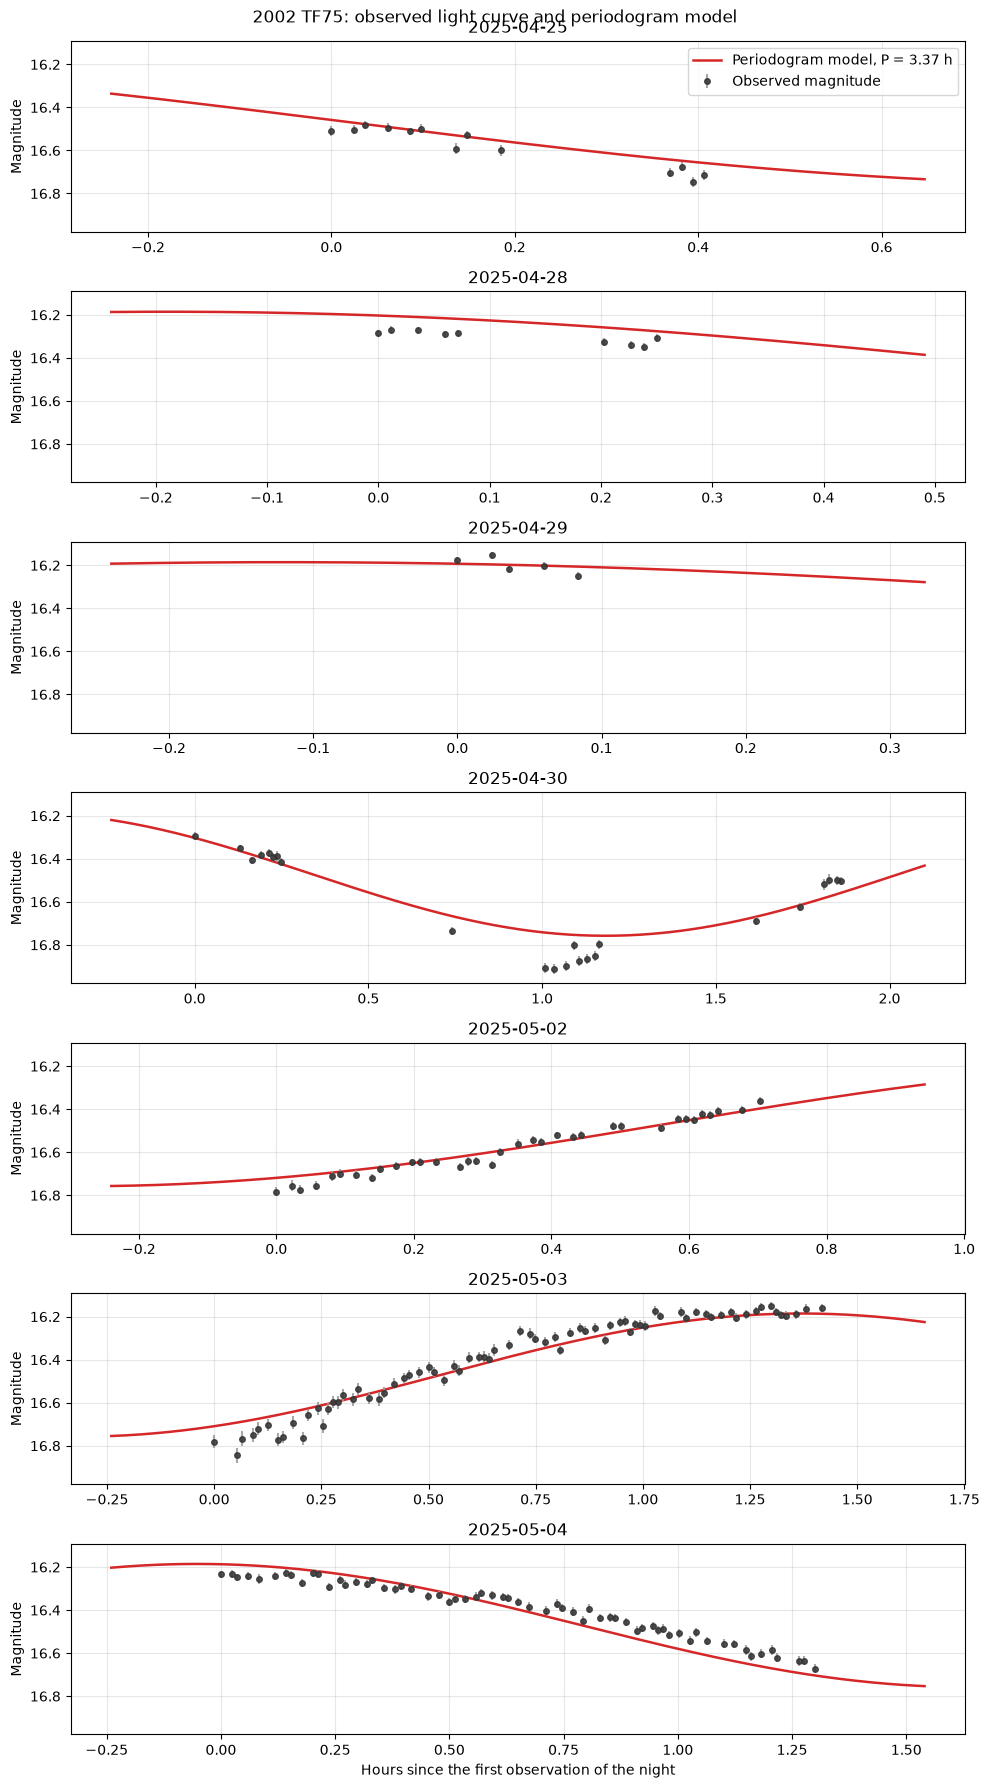

In [21]:
nights_band = df_band['night'].drop_duplicates().sort_values()
n_nights_band = len(nights_band)
fig, axs = plt.subplots(n_nights_band, 1, figsize=(10, 2.6 * n_nights_band), sharey=True)
if n_nights_band == 1:
    axs = [axs]

for ax, night in zip(axs, nights_band):
    sel = df_band['night'] == night
    t_night = df_band.loc[sel, 't_days'].to_numpy()
    y_night = df_band.loc[sel, prop].to_numpy()
    dy_night = df_band.loc[sel, 'rmsmag'].fillna(0.01).to_numpy()
    t_left, t_right = t_night.min(), t_night.max()
    pad = max(0.01, 0.05 * (t_right - t_left))
    t_grid = np.linspace(t_left - pad, t_right + pad, 400)
    y_grid = ls_band.model(t_grid, best_freq)
    hours = (t_night - t_left) * 24.0
    hours_grid = (t_grid - t_left) * 24.0
    ax.errorbar(
        hours, y_night, yerr=dy_night, fmt='o', ms=4, alpha=0.85,
        color='0.2', ecolor='0.6', label='Observed magnitude', zorder=3
    )
    ax.plot(
        hours_grid, y_grid, color='C3', lw=1.8,
        label=f'Periodogram model, P = {best_phot_period:.2f} h', zorder=2
    )
    ax.set_title(pd.to_datetime(night).strftime('%Y-%m-%d'))
    ax.set_ylabel('Magnitude')
    ax.grid(True, alpha=0.3)

axs[0].invert_yaxis()
axs[0].legend(loc='best', frameon=True)
axs[-1].set_xlabel('Hours since the first observation of the night')
fig.suptitle(f'{provid}: observed light curve and periodogram model')
fig.tight_layout()
fig.savefig(fig_dir + f'timemodel_H_{provid.replace(" ", "_")}.png', dpi=300)
